In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)



In [4]:
# 1. Load dataset
df = pd.read_excel("loan.xlsx")

print("Dataset shape:", df.shape)
print("\nFirst five records:\n", df.head())
print("\nMissing values:\n", df.isnull().sum())
print("\nClass distribution:\n", df["Loan_Status"].value_counts())




Dataset shape: (207, 13)

First five records:
     Loan_ID  Gender Married Dependents     Education Self_Employed  \
0  LP002314  Female      No          0  Not Graduate            No   
1  LP002315    Male     Yes          1      Graduate            No   
2  LP002317    Male     Yes         3+      Graduate            No   
3  LP002318  Female      No          1  Not Graduate           Yes   
4  LP002319    Male     Yes          0      Graduate           NaN   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             2213                0.0        66.0             360.0   
1             8300                0.0       152.0             300.0   
2            81000                0.0       360.0             360.0   
3             3867                0.0        62.0             360.0   
4             6256                0.0       160.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Rural           Y  
1            

In [5]:
# 2. Clean Dependents column
df["Dependents"] = pd.to_numeric(
    df["Dependents"].astype(str).str.replace("+", "", regex=False),
    errors="coerce"
)



In [6]:
# 3. Separate features and target
X = df.drop(columns=["Loan_ID", "Loan_Status"])
y = df["Loan_Status"].map({"N": 0, "Y": 1})

numeric_cols = [
    "Dependents", "ApplicantIncome", "CoapplicantIncome",
    "LoanAmount", "Loan_Amount_Term", "Credit_History"
]

categorical_cols = [
    "Gender", "Married", "Education",
    "Self_Employed", "Property_Area"
]



In [7]:
# 4. Fixed train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining size:", len(X_train))
print("Testing size:", len(X_test))




Training size: 165
Testing size: 42


In [8]:
# 5. Function to create Decision Tree pipeline
def make_model(criterion):
    numeric_preprocessing = SimpleImputer(strategy="median")

    categorical_preprocessing = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_preprocessing, numeric_cols),
        ("cat", categorical_preprocessing, categorical_cols)
    ])

    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            criterion=criterion,
            max_depth=None,
            min_samples_leaf=1,
            random_state=42
        ))
    ])



In [9]:
# 6. Function to evaluate any Decision Tree
def evaluate_model(name, model):
    predictions = model.predict(X_test)
    tree = model.named_steps["classifier"]

    matrix = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    summary = {
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(precision_score(
            y_test, predictions, zero_division=0
        ), 4),
        "Recall": round(recall_score(
            y_test, predictions, zero_division=0
        ), 4),
        "F1": round(f1_score(
            y_test, predictions, zero_division=0
        ), 4),
        "Macro F1": round(f1_score(
            y_test, predictions, average="macro"
        ), 4),
        "Depth": tree.get_depth(),
        "Leaves": tree.get_n_leaves(),
        "Nodes": tree.tree_.node_count
    }

    print("\n" + name)
    print(pd.Series(summary))
    print("Confusion Matrix:\n", matrix)

    return summary



In [10]:
# 7. Train baseline Gini and Entropy models
baseline_gini = make_model("gini")
baseline_entropy = make_model("entropy")

baseline_gini.fit(X_train, y_train)
baseline_entropy.fit(X_train, y_train)



Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['Dependents',
                                                   'ApplicantIncome',
                                                   'CoapplicantIncome',
                                                   'LoanAmount',
                                                   'Loan_Amount_Term',
                                                   'Credit_History']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'Married',
                                                   'Education', 'Self_Employed',
                                                   'Property_Area'])])),
                ('classifier',
                 DecisionTreeClassifier(criterion='entropy', random_state=42))])

In [11]:
# Evaluate baseline models
results = []

results.append(
    evaluate_model("Baseline Gini", baseline_gini)
)

results.append(
    evaluate_model("Baseline Entropy", baseline_entropy)
)




Baseline Gini
Model        Baseline Gini
Accuracy            0.7143
Precision           0.8077
Recall                0.75
F1                  0.7778
Macro F1            0.6889
Depth                   13
Leaves                  38
Nodes                   75
dtype: object
Confusion Matrix:
 [[ 9  5]
 [ 7 21]]

Baseline Entropy
Model        Baseline Entropy
Accuracy               0.7143
Precision              0.8077
Recall                   0.75
F1                     0.7778
Macro F1               0.6889
Depth                      15
Leaves                     38
Nodes                      75
dtype: object
Confusion Matrix:
 [[ 9  5]
 [ 7 21]]


In [12]:
# 8. Define hyperparameter combinations
param_grid = {
    "classifier__max_depth": [2, 3, 4, 5, None],
    "classifier__min_samples_leaf": [1, 2, 5, 10]
}

# 9. Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 10. Optimize both Decision Trees
best_models = {}

for criterion in ["gini", "entropy"]:
    search = GridSearchCV(
        estimator=make_model(criterion),
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=1
    )

    search.fit(X_train, y_train)

    best_models[criterion] = search.best_estimator_

    print("\nBest settings for", criterion)
    print(search.best_params_)
    print("Best CV Macro F1:", round(search.best_score_, 4))

    results.append(
        evaluate_model(
            "Tuned " + criterion.title(),
            search.best_estimator_
        )
    )




Best settings for gini
{'classifier__max_depth': 2, 'classifier__min_samples_leaf': 2}
Best CV Macro F1: 0.7408

Tuned Gini
Model        Tuned Gini
Accuracy          0.881
Precision         0.871
Recall           0.9643
F1               0.9153
Macro F1         0.8576
Depth                 2
Leaves                4
Nodes                 7
dtype: object
Confusion Matrix:
 [[10  4]
 [ 1 27]]

Best settings for entropy
{'classifier__max_depth': 4, 'classifier__min_samples_leaf': 2}
Best CV Macro F1: 0.7614

Tuned Entropy
Model        Tuned Entropy
Accuracy            0.8095
Precision           0.8571
Recall              0.8571
F1                  0.8571
Macro F1            0.7857
Depth                    4
Leaves                   7
Nodes                   13
dtype: object
Confusion Matrix:
 [[10  4]
 [ 4 24]]



Final Comparison:
           Model  Accuracy  Precision  Recall     F1  Macro F1  Depth  Leaves  Nodes
   Baseline Gini    0.7143     0.8077  0.7500 0.7778    0.6889     13      38     75
Baseline Entropy    0.7143     0.8077  0.7500 0.7778    0.6889     15      38     75
      Tuned Gini    0.8810     0.8710  0.9643 0.9153    0.8576      2       4      7
   Tuned Entropy    0.8095     0.8571  0.8571 0.8571    0.7857      4       7     13


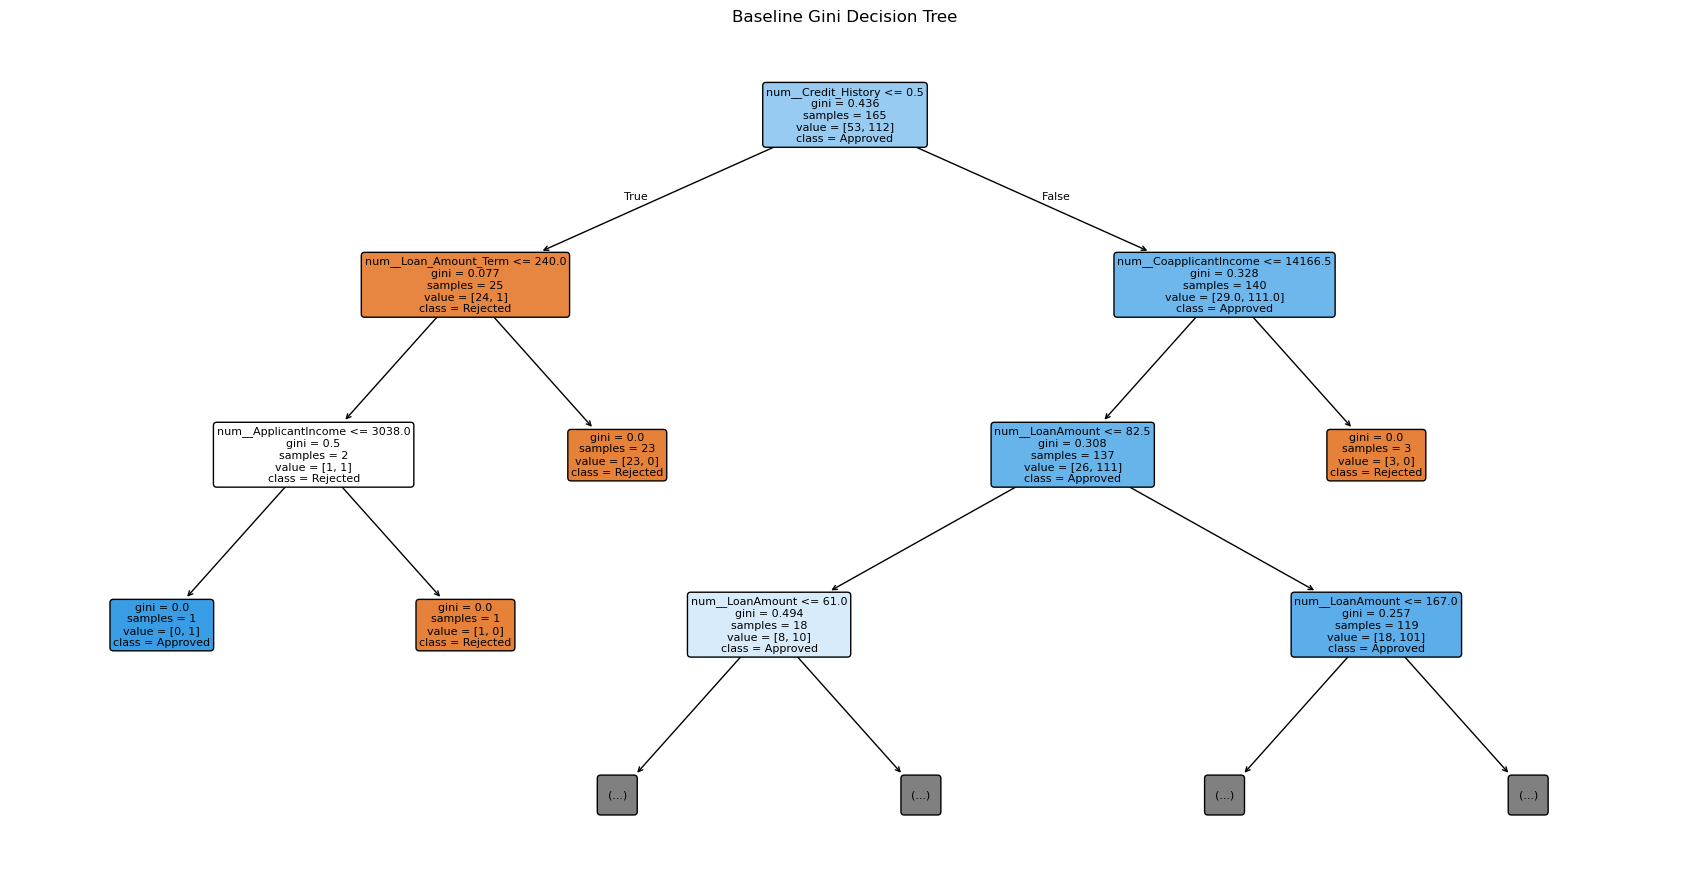

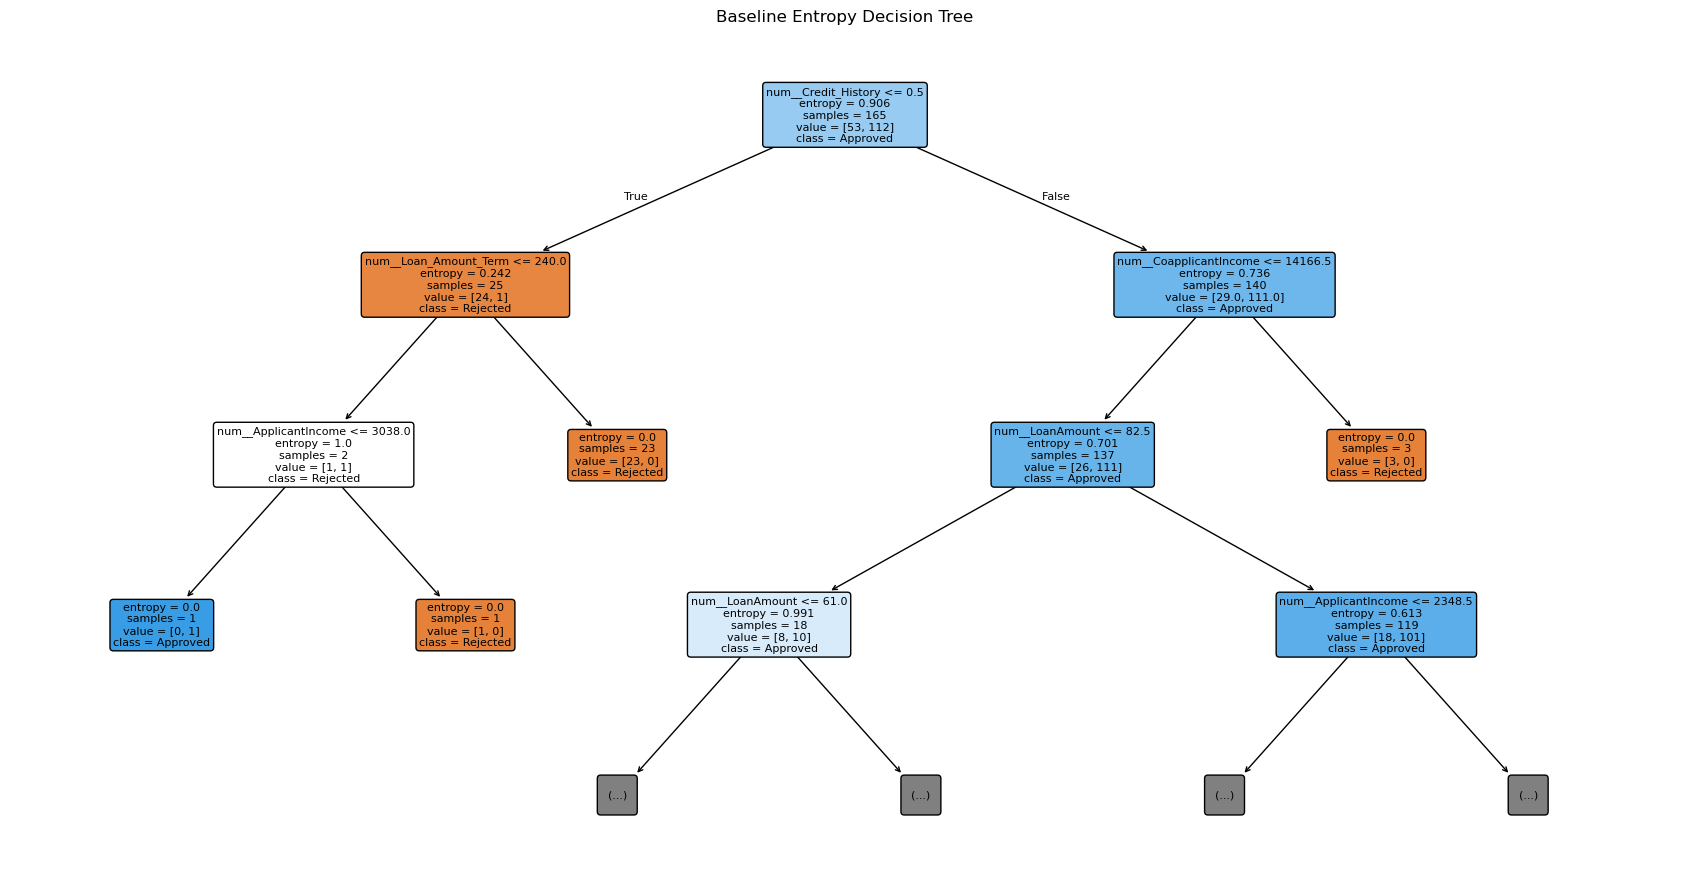

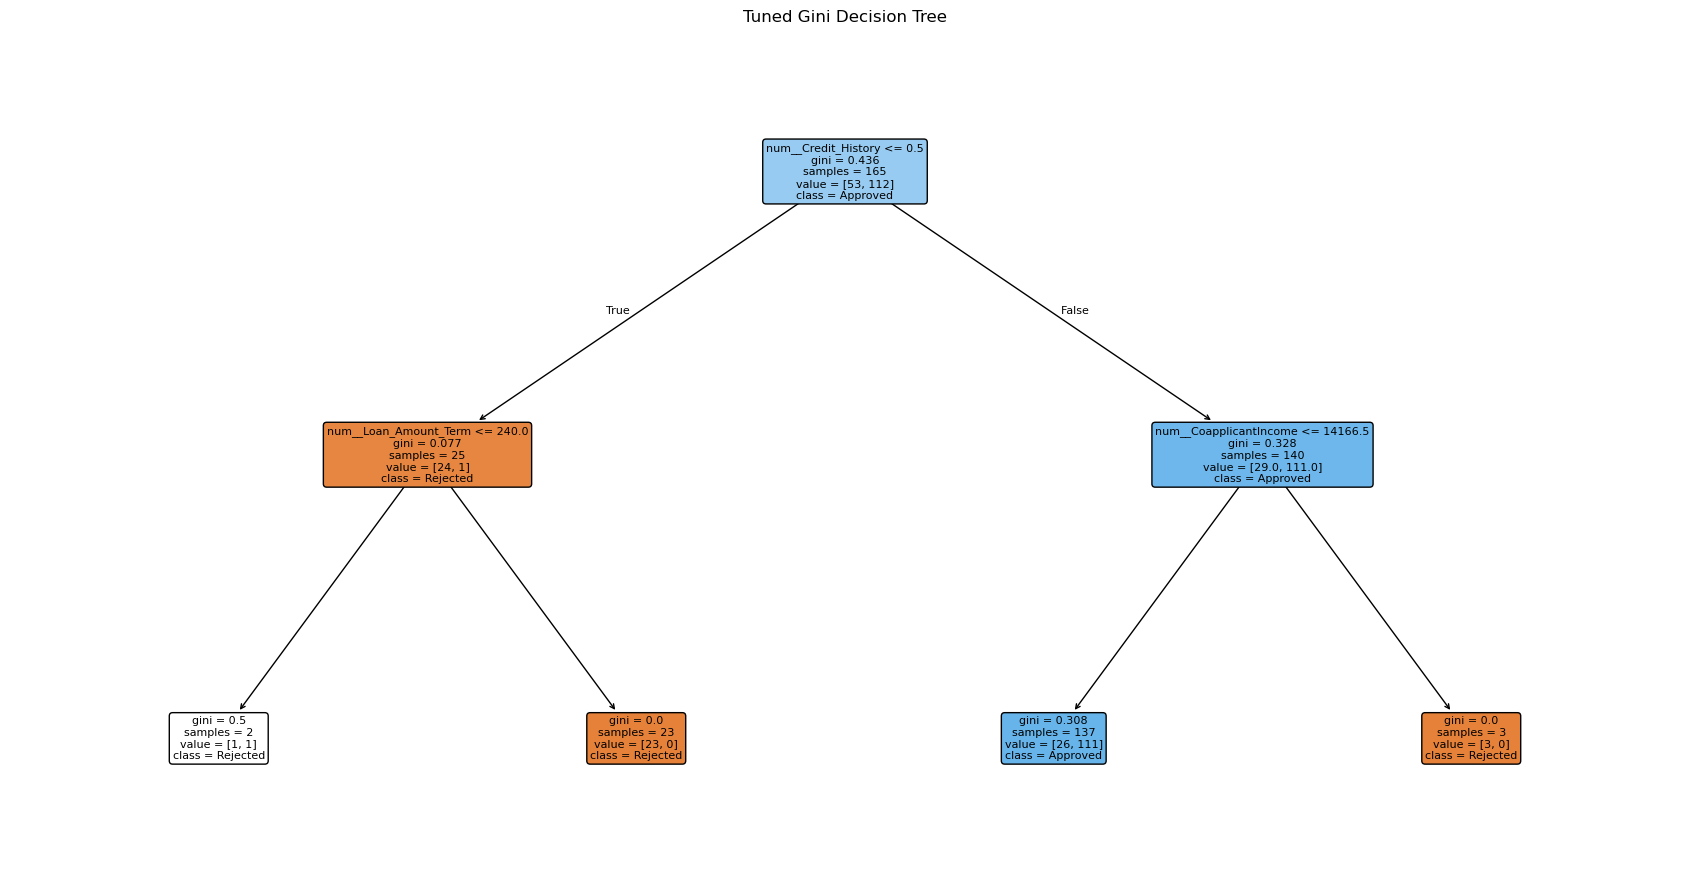

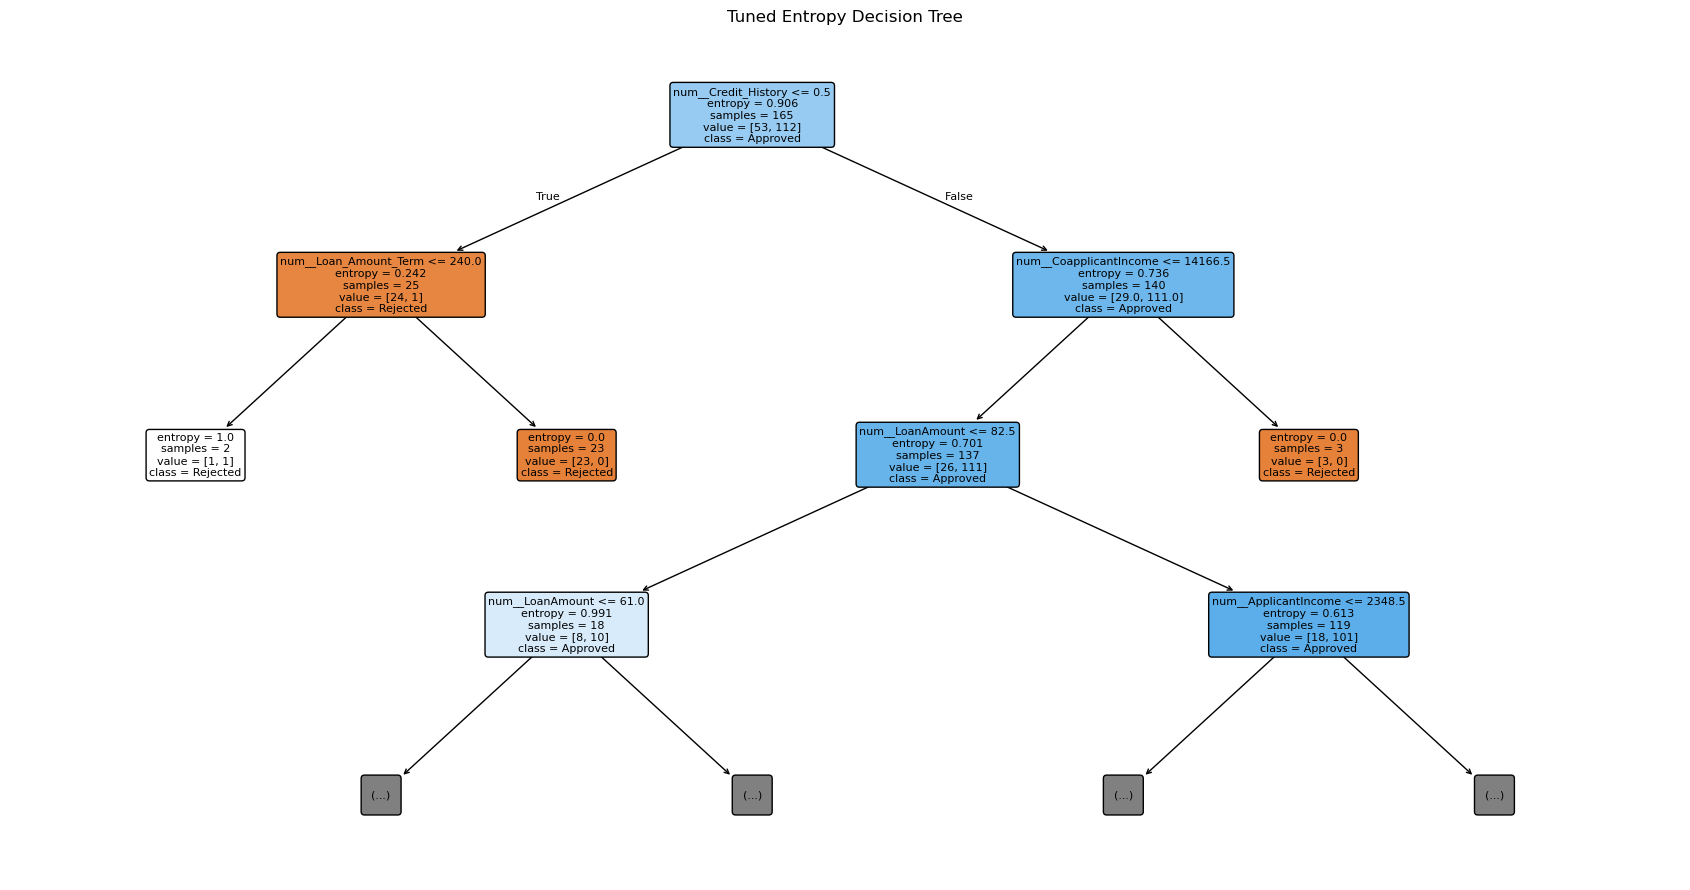

In [13]:
# 11. Final model comparison
print("\nFinal Comparison:")
print(pd.DataFrame(results).to_string(index=False))

# 12. Visualize Decision Trees
models_to_plot = [
    ("Baseline Gini", baseline_gini),
    ("Baseline Entropy", baseline_entropy),
    ("Tuned Gini", best_models["gini"]),
    ("Tuned Entropy", best_models["entropy"])
]

for title, model in models_to_plot:
    plt.figure(figsize=(17, 9))

    plot_tree(
        model.named_steps["classifier"],
        feature_names=model.named_steps[
            "preprocessor"
        ].get_feature_names_out(),
        class_names=["Rejected", "Approved"],
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=8
    )

    plt.title(title + " Decision Tree")
    plt.tight_layout()
    plt.show()



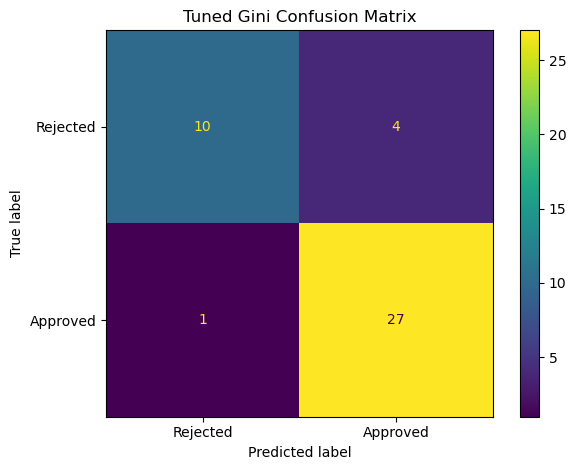

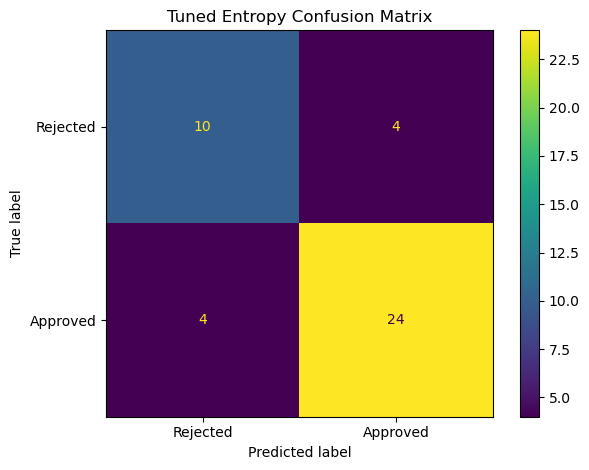

In [14]:
# 13. Confusion matrices for tuned models
for criterion, model in best_models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Rejected", "Approved"]
    )

    disp.plot()
    plt.title("Tuned " + criterion.title() + " Confusion Matrix")
    plt.tight_layout()
    plt.show()



In [15]:
# 14. Actual vs predicted results
pred_gini = best_models["gini"].predict(X_test)
pred_entropy = best_models["entropy"].predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test.map({
        0: "Rejected", 1: "Approved"
    }).to_numpy(),

    "Gini prediction": pd.Series(pred_gini).map({
        0: "Rejected", 1: "Approved"
    }).to_numpy(),

    "Entropy prediction": pd.Series(pred_entropy).map({
        0: "Rejected", 1: "Approved"
    }).to_numpy()
})

print("\nFirst 10 test predictions:")
print(comparison.head(10))


First 10 test predictions:
     Actual Gini prediction Entropy prediction
0  Approved        Approved           Approved
1  Approved        Approved           Approved
2  Approved        Approved           Approved
3  Approved        Approved           Approved
4  Rejected        Rejected           Rejected
5  Rejected        Approved           Approved
6  Approved        Approved           Approved
7  Approved        Approved           Approved
8  Rejected        Rejected           Rejected
9  Rejected        Rejected           Rejected
